In [28]:
!pip install -U datasets evaluate transformers sentencepiece accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.0/84.0 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 68.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 24.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 38.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 901.9 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

###**1. AutoModel in NLP**

AutoModel class, which is handy when you want to instantiate any model from a checkpoint.

The AutoModel class and all of its relatives are actually simple wrappers over the wide variety of models available in the hugging face library. It’s a clever wrapper as it can automatically guess the appropriate model architecture for your checkpoint, and then instantiates a model with this architecture.

However, if you know the type of model you want to use already, you can use the class that defines its architecture directly. Here, we can see how this works with a BERT model.

#### 1. Creating a Transformer (BERT model with config)

The first thing we’ll need to do to initialize a BERT model is load a configuration object.

In [ ]:
from transformers import BertModel, BertConfig

# Building the config
config = BertConfig()

# Building the model from config
model = BertModel(config=config)

Note that this would take a long time to train from scratch. It is usually recommended to load from some checkpoints, i.e., some pretrained weights.

In [ ]:
config

BertConfig {
  "attention_probs_dropout_prob": 0.1,
  "classifier_dropout": null,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 0,
  "position_embedding_type": "absolute",
  "transformers_version": "4.52.4",
  "type_vocab_size": 2,
  "use_cache": true,
  "vocab_size": 30522
}

#### 2. Loading a pretrained

Loading a Transformer model that is already trained is simple — we can do this using the `from_pretrained()` method

In [ ]:
from transformers import BertModel

model = BertModel.from_pretrained("bert-base-cased")

# the model is now ready to be used on tasks it was trained on, or finetuned

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/436M [00:00<?, ?B/s]

Note: For the first time, it has to do some downloading, next time it will get from cached stored at `~/.cache/huggingface/transformers`. We can customize your cache folder by setting the `HF_HOME` environment variable.


We could replace BertModel with the equivalent AutoModel class to produce checkpoint-agnostic code. If our code works for one checkpoint, it should work seamlessly with another. This applies even if the architecture is different, as long as the checkpoint was trained for a similar task (for example, a sentiment analysis task).

In the code sample above we didn’t use BertConfig, and instead loaded a pretrained model via the bert-base-cased identifier. This is a model checkpoint that was trained by the authors of BERT themselves; we can find more details about it in its model card.

#### 3. Saving methods

Saving a model is as easy as loading one — we use the `save_pretrained()` method, which is analogous to the `from_pretrained()` method.

This methids saves two files to our disk:
- `config.json`
- `model.safetensors`

If we take a look at the config.json file, we’ll recognize the attributes necessary to build the model architecture. This file also contains some metadata, such as where the checkpoint originated and what Transformers version we were using when we last saved the checkpoint.

The `model.safetensors` file is known as the state dictionary; it contains all your model’s weights. The two files go hand in hand; the `configuration` is necessary to know your `model’s architecture`, while the `model weights` are your `model’s parameters`.



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
model.save_pretrained(save_directory="/content/model_weights")

In [ ]:
!ls /content/model_weights

config.json  model.safetensors


We can explicilty tell the model to load safe tensors using `use_safetensors=True` in `from_pretrained` method.

### **2. Tokenizer**

Models can only process numbers, so we need to find a way to convert the raw text to numbers. That’s what the tokenizers do, and there are a lot of ways to go about this. The goal is to find the most meaningful representation — that is, the one that makes the most sense to the model — and, if possible, the smallest representation.


#### Word-Based tokenizer

The first type of tokenizer that comes to mind is word-based. It’s generally very easy to set up and use with only a few rules, and it often yields decent results.

There are different ways to split the text. For example, we could use `whitespace` to tokenize the text into words by applying Python’s `split()` function

In [ ]:
tokenized_text = "We are learning deep learning".split()
tokenized_text

['We', 'are', 'learning', 'deep', 'learning']

#### Character-Based

Word-based will get you way too many integers. One way to reduce the amount of unknown tokens is to go one level deeper, using a character-based tokenizer.

Character-based tokenizers split the text into characters, rather than words. This has two primary benefits:

- The vocabulary is much smaller.
- There are much fewer out-of-vocabulary (unknown) tokens, since every word can be built from characters.

This approach isn’t perfect either. Since the representation is now based on characters rather than words, one could argue that, intuitively, it’s less meaningful. Each character doesn’t mean a lot on its own, whereas that is the case with words. However, this again differs according to the language; in Chinese, for example, each character carries more information than a character in a Latin language.

Another thing to consider is that we’ll end up with a very large amount of tokens to be processed by our model: whereas a word would only be a single token with a word-based tokenizer, it can easily turn into 10 or more tokens when converted into characters.

To get the best of both worlds, we can use a third technique that combines the two approaches: `subword tokenization`.



#### Subword-based

Subword tokenization algorithms rely on the principle that frequently used words should not be split into smaller subwords, but rare words should be decomposed into meaningful subwords.

These subwords end up providing a lot of semantic meaning: for instance, in the example above “tokenization” was split into “token” and “ization”, two tokens that have a semantic meaning while being space-efficient (only two tokens are needed to represent a long word). This allows us to have relatively good coverage with small vocabularies, and close to no unknown tokens.

This approach is especially useful in agglutinative languages such as Turkish, where you can form (almost) arbitrarily long complex words by stringing together subwords.

Unsurprisingly, there are many more subword tokenization methods — ways to split text into smaller pieces that are smarter than characters and more flexible than whole words. Useful for handling rare words, misspellings, and languages without spaces.

##### **Byte-level Pair Encoding BPE, as used in GPT-2**

How it works:

- Starts with individual characters.
- Repeatedly merges the most common pairs of characters (or subwords).
- Learns which pieces occur frequently and builds a vocabulary of subwords.
- Used in: GPT-2, RoBERTa

Eg:

Input: lower, lowest

Might split into: low, er, est

So even if you see a new word like lowering, it can still be understood as low + er + ing.







##### **WordPiece, as used in BERT**

Similar idea to BPE, but a bit more careful in merging.

Optimizes for how likely a sequence of tokens will appear in real sentences.

How it works:
- Starts with a list of characters.
- Merges pieces based on improving the likelihood (probability) of real text.
- Adds ## to indicate it’s a continuation of a word.
- Used in: BERT

Exg:

Input: playing

Might be tokenized as: play, ##ing


##### **SentencePiece or Unigram, as used in several multilingual models**

- Works without needing spaces between words.
- Great for non-English languages (like Japanese, Korean, etc.).
- Treats the text as a raw sequence of characters (including spaces).
- Learns subword units in a similar way as BPE or unigram models.
- Used in: T5, ALBERT, mBERT

Eg:

Input: Hello there

Might tokenize as: _He, llo, _there (underscore _ = space)



### **3. Loading and saving Tokenizers**

Loading and saving tokenizers is as simple as it is with models. Actually, it’s based on the same two methods: `from_pretrained()` and `save_pretrained()`.

These methods will load or save the algorithm used by the tokenizer (a bit like the architecture of the model) as well as its vocabulary (a bit like the weights of the model).

Loading the BERT tokenizer trained with the same checkpoint as BERT is done the same way as loading the model, except we use the BertTokenizer(we can also use the AutoTokenizer if we are lazy to remember...) class:

In [ ]:
from transformers import BertTokenizer

tokenizer = BertTokenizer.from_pretrained("bert-base-cased")  # can replace BertTokenizer with AutoTokenizer

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

In [ ]:
tokenizer

BertTokenizer(name_or_path='bert-base-cased', vocab_size=28996, model_max_length=512, is_fast=False, padding_side='right', truncation_side='right', special_tokens={'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}, clean_up_tokenization_spaces=True, added_tokens_decoder={
	0: AddedToken("[PAD]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	100: AddedToken("[UNK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	101: AddedToken("[CLS]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	102: AddedToken("[SEP]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	103: AddedToken("[MASK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
}
)

In [ ]:
tokenizer("Using a Transformer network is simple")

{'input_ids': [101, 7993, 170, 13809, 23763, 2443, 1110, 3014, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1]}

In [ ]:
# testing tokenize
tokens = tokenizer.tokenize("Using a Transformer network is simple")
tokens  # '##' indicates subwords

['Using', 'a', 'Trans', '##former', 'network', 'is', 'simple']

In [ ]:
# tokens to ids
ids = tokenizer.convert_tokens_to_ids(tokens)
ids

[7993, 170, 13809, 23763, 2443, 1110, 3014]

In [ ]:
# ids to tokens
words = tokenizer.convert_ids_to_tokens([7993, 170, 13809, 23763, 2443, 1110, 3014])
words

['Using', 'a', 'Trans', '##former', 'network', 'is', 'simple']

In [ ]:
tokenizer.decode([101, 7993, 170, 13809, 23763, 2443, 1110, 3014, 102])

'[CLS] Using a Transformer network is simple [SEP]'

In [ ]:
# saving tokenizer
tokenizer.save_pretrained("content/tokenizer_weights")

('content/tokenizer_weights/tokenizer_config.json',
 'content/tokenizer_weights/special_tokens_map.json',
 'content/tokenizer_weights/vocab.txt',
 'content/tokenizer_weights/added_tokens.json')

### **3. Manual tokenization**

In the previous section, we explored the simplest of use cases: doing inference on a single sequence of a small length. However, some questions emerge already:

- How do we handle multiple sequences?
- How do we handle multiple sequences of different lengths?
- Are vocabulary indices the only inputs that allow a model to work well?
- Is there such a thing as too long a sequence?

Let’s see what kinds of problems these questions pose, and how we can solve them using the 🤗 Transformers API.

**Models expect a batch of inputs**

In the previous exercise we saw how sequences get translated into lists of numbers. Let’s convert this list of numbers to a tensor and send it to the model.

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)
model = AutoModelForSequenceClassification.from_pretrained(checkpoint)

sequence = "I've been waiting for a HuggingFace course my whole life."

tokens = tokenizer.tokenize(sequence)
ids = tokenizer.convert_tokens_to_ids(tokens)
input_ids = torch.tensor(ids)

model(input_ids)  # This line will fail.

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

IndexError: too many indices for tensor of dimension 1

Oh no! Why did this fail?

The problem is that we sent a single sequence to the model, whereas Transformers models expect multiple sentences by default. Here we tried to do everything the tokenizer did behind the scenes when we applied it to a sequence. But if you look closely, you’ll see that the tokenizer didn’t just convert the list of input IDs into a tensor, it added a dimension on top of it and also added attention mask which is expected by the model.

In [ ]:
input_ids

tensor([ 1045,  1005,  2310,  2042,  3403,  2005,  1037, 17662, 12172,  2607,
         2026,  2878,  2166,  1012])

In [ ]:
tokenized_inputs = tokenizer(sequence, return_tensors="pt")
tokenized_inputs

{'input_ids': tensor([[  101,  1045,  1005,  2310,  2042,  3403,  2005,  1037, 17662, 12172,
          2607,  2026,  2878,  2166,  1012,   102]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}

Let’s try again and add a new dimension

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)
model = AutoModelForSequenceClassification.from_pretrained(checkpoint)

sequence = "I've been waiting for a HuggingFace course my whole life."

tokens = tokenizer.tokenize(sequence)
ids = tokenizer.convert_tokens_to_ids(tokens)
input_ids = torch.tensor([ids])
print("Input IDs:", input_ids)

output = model(input_ids)
print(output)
print("Logits:", output.logits)

Input IDs: tensor([[ 1045,  1005,  2310,  2042,  3403,  2005,  1037, 17662, 12172,  2607,
          2026,  2878,  2166,  1012]])
SequenceClassifierOutput(loss=None, logits=tensor([[-2.7276,  2.8789]], grad_fn=<AddmmBackward0>), hidden_states=None, attentions=None)
Logits: tensor([[-2.7276,  2.8789]], grad_fn=<AddmmBackward0>)


### **4. Padding and Truncating the inputs**

In [1]:
from transformers import AutoTokenizer

checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

sequence = "I've been waiting for a HuggingFace course my whole life."

#input id as well as the attention mask
model_inputs = tokenizer(sequence)
model_inputs

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

{'input_ids': [101, 1045, 1005, 2310, 2042, 3403, 2005, 1037, 17662, 12172, 2607, 2026, 2878, 2166, 1012, 102], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}

In [2]:
from transformers import AutoTokenizer

checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

# multiple sequences
sequences = ["I've been waiting for a HuggingFace course my whole life.", "So have I!"]

#input id as well as the attention mask
model_inputs = tokenizer(sequences)
model_inputs

{'input_ids': [[101, 1045, 1005, 2310, 2042, 3403, 2005, 1037, 17662, 12172, 2607, 2026, 2878, 2166, 1012, 102], [101, 2061, 2031, 1045, 999, 102]], 'attention_mask': [[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1]]}

Tokenizer can pad in different ways:
- longest sequence in the batch: `padding="longest"`
- max seq length model can process: `padding="max_length"`
- maximum specific length required by user: `padding="max_length", max_length=8`

In [3]:
from transformers import AutoTokenizer

checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

# multiple sequences
sequences = ["I've been waiting for a HuggingFace course my whole life.", "So have I!"]

#input id as well as the attention mask
model_inputs = tokenizer(sequences, padding="longest")
model_inputs   # observe padding in 2nd sequence

{'input_ids': [[101, 1045, 1005, 2310, 2042, 3403, 2005, 1037, 17662, 12172, 2607, 2026, 2878, 2166, 1012, 102], [101, 2061, 2031, 1045, 999, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]], 'attention_mask': [[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]}

In [4]:
from transformers import AutoTokenizer

checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

# multiple sequences
sequences = ["I've been waiting for a HuggingFace course my whole life.", "So have I!"]

#input id as well as the attention mask
model_inputs = tokenizer(sequences, padding="max_length")  # (512 for BERT or DistilBERT)
model_inputs   # observe padding in 2nd sequence

{'input_ids': [[101, 1045, 1005, 2310, 2042, 3403, 2005, 1037, 17662, 12172, 2607, 2026, 2878, 2166, 1012, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 

In [5]:
from transformers import AutoTokenizer

checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

# multiple sequences
sequences = ["I've been waiting for a HuggingFace course my whole life.", "So have I!"]

#input id as well as the attention mask
model_inputs = tokenizer(sequences, padding="max_length", max_length=8) # see that it wont truncate the existing long 1st sentence
model_inputs   # observe padding in 2nd sequence, only specified max length padding is done

{'input_ids': [[101, 1045, 1005, 2310, 2042, 3403, 2005, 1037, 17662, 12172, 2607, 2026, 2878, 2166, 1012, 102], [101, 2061, 2031, 1045, 999, 102, 0, 0]], 'attention_mask': [[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 0, 0]]}

Tokenizer can also truncate sequences that are longer than the model max length or longer than the specified max length

In [6]:
# Truncation
from transformers import AutoTokenizer

checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

# multiple sequences
sequences = ["I've been waiting for a HuggingFace course my whole life.", "So have I!"]

#input id as well as the attention mask
model_inputs = tokenizer(sequences, truncation=True)  # Will truncate the sequences that are longer than the model max length
# (512 for BERT or DistilBERT)
model_inputs

{'input_ids': [[101, 1045, 1005, 2310, 2042, 3403, 2005, 1037, 17662, 12172, 2607, 2026, 2878, 2166, 1012, 102], [101, 2061, 2031, 1045, 999, 102]], 'attention_mask': [[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1]]}

In [7]:
# Truncation with max_length
from transformers import AutoTokenizer

checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

# multiple sequences
sequences = ["I've been waiting for a HuggingFace course my whole life.", "So have I!"]

#input id as well as the attention mask
model_inputs = tokenizer(sequences, truncation=True, max_length=8)  # Will truncate the sequences that are longer than the specified max length
model_inputs

{'input_ids': [[101, 1045, 1005, 2310, 2042, 3403, 2005, 102], [101, 2061, 2031, 1045, 999, 102]], 'attention_mask': [[1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1]]}

The tokenizer object can handle the conversion to specific framework tensors, which can then be directly sent to the model. For example, in the following code sample we are prompting the tokenizer to return tensors from the different frameworks — "pt" returns PyTorch tensors, "tf" returns TensorFlow tensors, and "np" returns NumPy arrays

In [8]:
# Truncation with max_length
from transformers import AutoTokenizer

checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

# multiple sequences
sequences = ["I've been waiting for a HuggingFace course my whole life.", "So have I!"]

model_inputs = tokenizer(sequences, padding=True, return_tensors="pt")
print(model_inputs)

model_inputs = tokenizer(sequences, padding=True, return_tensors="tf")
print(model_inputs)

model_inputs = tokenizer(sequences, padding=True, return_tensors="np")
print(model_inputs)

{'input_ids': tensor([[  101,  1045,  1005,  2310,  2042,  3403,  2005,  1037, 17662, 12172,
          2607,  2026,  2878,  2166,  1012,   102],
        [  101,  2061,  2031,  1045,   999,   102,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])}
{'input_ids': <tf.Tensor: shape=(2, 16), dtype=int32, numpy=
array([[  101,  1045,  1005,  2310,  2042,  3403,  2005,  1037, 17662,
        12172,  2607,  2026,  2878,  2166,  1012,   102],
       [  101,  2061,  2031,  1045,   999,   102,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0]], dtype=int32)>, 'attention_mask': <tf.Tensor: shape=(2, 16), dtype=int32, numpy=
array([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]], dtype=int32)>}
{'input_ids': array([[  101,  1045,  1005,  2310,  2042,

The following list of lists cannot be converted to a tensor

In [ ]:
import torch

batch_ids = [
    [200, 200, 200],
    [200, 200]
]

torch.tensor(batch_ids) # only rectangular/sqaure shapes works

ValueError: expected sequence of length 3 at dim 1 (got 2)

In order to work around this, we’ll use padding to make our tensors have a rectangular shape. Padding makes sure all our sentences have the same length by adding a special word called the padding token to the sentences with fewer values.

For example, if you have 10 sentences with 10 words and 1 sentence with 20 words, padding will ensure all the sentences have 20 words. In our example, the resulting tensor looks like this

In [ ]:
import torch

padding_token = 100

batch_ids = [
    [200, 200, 200],
    [200, 200, padding_token]
]

torch.tensor(batch_ids)


tensor([[200, 200, 200],
        [200, 200, 100]])

The padding token ID can be found in `tokenizer.pad_token_id`

Let’s use it and send our two sentences through the model individually and batched together:

In [ ]:
tokenizer.pad_token_id

0

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(checkpoint)

seq1_ids = [[200, 200, 200]]
seq2_ids = [[200, 200]]
batched_ids = [
    [200, 200, 200],
    [200, 200, tokenizer.pad_token_id]
]

print(model(torch.tensor(seq1_ids)).logits)
print(model(torch.tensor(seq2_ids)).logits)
print(model(torch.tensor(batched_ids)).logits)

We strongly recommend passing in an `attention_mask` since your input_ids may be padded. See https://huggingface.co/docs/transformers/troubleshooting#incorrect-output-when-padding-tokens-arent-masked.


tensor([[ 1.5694, -1.3895]], grad_fn=<AddmmBackward0>)
tensor([[ 0.5803, -0.4125]], grad_fn=<AddmmBackward0>)
tensor([[ 1.5694, -1.3895],
        [ 1.3374, -1.2163]], grad_fn=<AddmmBackward0>)


There’s something wrong with the logits in our batched predictions: the second row should be the same as the logits for the second sentence, but we’ve got completely different values!

This is because the key feature of Transformer models is attention layers that contextualize each token. These will take into account the padding tokens since they attend to all of the tokens of a sequence when we dont have attention mask to avoid attention to padding tokens.

To get the same result when passing individual sentences of different lengths through the model or when passing a batch with the same sentences and padding applied, we need to tell those attention layers to ignore the padding tokens. This is done by using an attention mask.

### **5. Attention Masks**

Attention masks are tensors with the exact same shape as the input IDs tensor, filled with 0s and 1s: 1s indicate the corresponding tokens should be attended to, and 0s indicate the corresponding tokens should not be attended to (i.e., they should be ignored by the attention layers of the model).

Let’s complete the previous example with an attention mask

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(checkpoint)

batched_ids = [
    [200, 200, 200],
    [200, 200, tokenizer.pad_token_id]
]
attention_mask = [
    [1, 1, 1],
    [1, 1, 0]
]

outputs = model(torch.tensor(batched_ids), attention_mask=torch.tensor(attention_mask))
print(outputs.logits)  # observe the second sequence logits now

tensor([[ 1.5694, -1.3895],
        [ 0.5803, -0.4125]], grad_fn=<AddmmBackward0>)


### **6.Special tokens**

If we take a look at the input IDs returned by the tokenizer, we will see they are a tiny bit different from what we had earlier.

In [13]:
from transformers import AutoTokenizer

checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

# multiple sequences
sequences = ["I've been waiting for a HuggingFace course my whole life.", "So have I!"]

model_inputs = tokenizer(sequences, padding=True, return_tensors="pt")
print(tokenizer.all_special_tokens, tokenizer.all_special_ids)

['[UNK]', '[SEP]', '[PAD]', '[CLS]', '[MASK]'] [100, 102, 0, 101, 103]


In [12]:
model_inputs["input_ids"]

tensor([[  101,  1045,  1005,  2310,  2042,  3403,  2005,  1037, 17662, 12172,
          2607,  2026,  2878,  2166,  1012,   102],
        [  101,  2061,  2031,  1045,   999,   102,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0]])

In [15]:
tokenizer.decode(model_inputs["input_ids"][1])

'[CLS] so have i! [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]'

The tokenizer added the special word [CLS] at the beginning and the special word [SEP] at the end. This is because the model was pretrained with those, so to get the same results for inference we need to add them as well. Note that some models don’t add special words, or add different ones; models may also add these special words only at the beginning, or only at the end. In any case, the tokenizer knows which ones are expected and will deal with this for you.

### **7. Longer sequences**

With Transformer models, there is a limit to the lengths of the sequences we can pass the models. Most models handle sequences of up to 512 or 1024 tokens, and will crash when asked to process longer sequences. There are two solutions to this problem.

- Use a model with a longer supported sequence length.
- Truncate your sequences.

Models have different supported sequence lengths, and some specialize in handling very long sequences. Longformer is one example. If you’re working on a task that requires very long sequences, take a look at those models in library.

Otherwise, it is recommended to truncate your sequences by specifying the `max_sequence_length` parameter.

In [ ]:
# Truncate
max_sequence_length = 512
sequence = sequence[:max_sequence_length]

sequence

"I've been waiting for a HuggingFace course my whole life."

### **8. Wrapping up: From tokenizer to model**

Now that we’ve seen all the individual steps the tokenizer object uses when applied on texts, let’s see one final time how it can handle multiple sequences (padding!), very long sequences (truncation!), and multiple types of tensors with its main API

In [17]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)
model      = AutoModelForSequenceClassification.from_pretrained(checkpoint)

# multiple sequences
sequences = ["I've been waiting for a HuggingFace course my whole life.", "So have I!"]

inputs = tokenizer(sequences, padding=True, truncation=True, return_tensors="pt")
output = model(**inputs)
output

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

SequenceClassifierOutput(loss=None, logits=tensor([[-1.5607,  1.6123],
        [-3.6183,  3.9137]], grad_fn=<AddmmBackward0>), hidden_states=None, attentions=None)

In [19]:
model.config.id2label

{0: 'NEGATIVE', 1: 'POSITIVE'}

In [20]:
model

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSdpaAttention(
            (dropout): Dropout(p=0.1, inplace=False)
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)


### Training a new tokenizer from existing pretrained tokenizer for a new language.

Sometimes we may want to train your own tokenizer for our new language, for example, Chinese or even programming language.

Huggingface provide `AutoTokenizer.train_new_from_iterator()` to train a new tokenizer.

To see this in action, let’s say we want to train GPT-2 from scratch, but in a language other than English. Our first task will be to gather lots of data in that language in a training corpus. To provide examples everyone will be able to understand, we won’t use a language like Russian or Chinese here, but rather a specialized English language: Python code.



#### 1. Loading CodeSearchNet using generator

We’ll use the usual `datasets.load_dataset()` function to download and cache the `CodeSearchNet dataset`. This dataset was created for the CodeSearchNet challenge and contains millions of functions from open source libraries on GitHub in several programming languages. Here, we will load the Python part of this dataset.

In [1]:
import datasets
from datasets import load_dataset

dataset = load_dataset("code_search_net", "python")

README.md:   0%|          | 0.00/12.9k [00:00<?, ?B/s]

code_search_net.py:   0%|          | 0.00/8.44k [00:00<?, ?B/s]

In [2]:
dataset

DatasetDict({
    train: Dataset({
        features: ['repository_name', 'func_path_in_repository', 'func_name', 'whole_func_string', 'language', 'func_code_string', 'func_code_tokens', 'func_documentation_string', 'func_documentation_tokens', 'split_name', 'func_code_url'],
        num_rows: 412178
    })
    test: Dataset({
        features: ['repository_name', 'func_path_in_repository', 'func_name', 'whole_func_string', 'language', 'func_code_string', 'func_code_tokens', 'func_documentation_string', 'func_documentation_tokens', 'split_name', 'func_code_url'],
        num_rows: 22176
    })
    validation: Dataset({
        features: ['repository_name', 'func_path_in_repository', 'func_name', 'whole_func_string', 'language', 'func_code_string', 'func_code_tokens', 'func_documentation_string', 'func_documentation_tokens', 'split_name', 'func_code_url'],
        num_rows: 23107
    })
})

Here. we’ll just use the `whole_func_string` column to train our tokenizer. We can look at an example of one these functions by indexing into the train split

In [4]:
print(dataset["train"][0]["whole_func_string"])

def update(self, field_dict, where_clause=None):
        '''
        update db entry

        :param field_dict: dictionary of fields and values
        :param where_clause: where clause for the update
        '''
        query = '''
        UPDATE %s SET %s
        ''' % (
            self._name,
            ','.join('%s=:%s' % (k, k) for k in field_dict)
        )
        if where_clause:
            query += ' WHERE %s' % (where_clause)
        self._cursor.execute(query, field_dict)
        self._connection.commit()


The first thing we need to do is transform the dataset into an iterator of lists of texts — for instance, a list of list of texts. Using lists of texts will enable our tokenizer to go faster (training on batches of texts instead of processing individual texts one by one), and it should be an iterator if we want to avoid having everything in memory at once.

Doing the following would create a list of lists of 1,000 texts each, but would load everything in memory.

```python
training_corpus = [
    raw_datasets["train"][i: i + 1000]["whole_func_string"] for i in range(0, len(raw_datasets["train"]), 1000)
]
```

We can either use hf's map function to avoid sunch OOM issues and do the processing in batches or python generator to do the same that yields only small amount into memory at a time.

Using a Python generator, we can avoid Python loading anything into memory until it’s actually necessary. To create such a generator, you just to need to replace the brackets with parentheses.

In [ ]:
training_corpus = (dataset["train"][i:i+1000]["whole_func_string"] for i in range(0, len(dataset["train"]), 1000))

This line of code doesn’t fetch any elements of the dataset; it just creates an object you can use in a Python for loop. The texts will only be loaded when you need them (that is, when you’re at the step of the for loop that requires them), and only 1,000 texts at a time will be loaded. This way you won’t exhaust all your memory even if you are processing a huge dataset.

The problem with a generator object is that it can only be used once i.e list will be exhausted when accessed the second time. See below example.

In [ ]:
gen = (i for i in range(10))
print(list(gen))
print(list(gen))

That’s why we define a function that returns a generator instead.

In [8]:
from tqdm.auto import tqdm

def get_training_corpus(batch_size=1000):
    train_ds = dataset["train"]
    for i in tqdm(range(0, len(train_ds), batch_size)):
        samples = train_ds[i:i+batch_size]["whole_func_string"]
        yield samples

training_corpus = get_training_corpus(1000)

```python
def get_training_corpus(batch_size=1000):
    return (
        raw_datasets["train"][i:i+batch_size]["whole_func_string"]
        for i in range(0, len(raw_datasets["train"]), batch_size)
    )
```

Also works, but yield based function which will produce the exact same generator as this, but allows you to use more complex logic than you can in a list comprehension.


#### 2. Training a new tokenizer
Now that we have our corpus in the form of an iterator of batches of texts, we are ready to train a new tokenizer. To do this, we first need to load the tokenizer we want to pair with our model (here, GPT-2)

In [5]:
from transformers import AutoTokenizer

old_tokenizer = AutoTokenizer.from_pretrained("gpt2")

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Even though we are going to train a new tokenizer, it’s a good idea to do this to avoid starting entirely from scratch. This way, we won’t have to specify anything about the tokenization algorithm or the special tokens we want to use; our new tokenizer will be exactly the same as GPT-2, and the only thing that will **`change is the vocabulary`**, which will be determined by the training on our corpus.

First let’s have a look at how this tokenizer would treat an example function.

In [7]:
example = '''def add_numbers(a, b):
    """Add the two numbers `a` and `b`."""
    return a + b'''

tokens = old_tokenizer.tokenize(example)
tokens

['def',
 'Ġadd',
 '_',
 'n',
 'umbers',
 '(',
 'a',
 ',',
 'Ġb',
 '):',
 'Ċ',
 'Ġ',
 'Ġ',
 'Ġ',
 'Ġ"""',
 'Add',
 'Ġthe',
 'Ġtwo',
 'Ġnumbers',
 'Ġ`',
 'a',
 '`',
 'Ġand',
 'Ġ`',
 'b',
 '`',
 '."',
 '""',
 'Ċ',
 'Ġ',
 'Ġ',
 'Ġ',
 'Ġreturn',
 'Ġa',
 'Ġ+',
 'Ġb']

This tokenizer has a few special symbols, like Ġ and Ċ, which denote spaces and newlines, respectively. As we can see, this is not too efficient: the tokenizer returns individual tokens for each space, when it could group together indentation levels (since having sets of four or eight spaces is going to be very common in code). It also split the function name a bit weirdly, not being used to seeing words with the _ character.

Let’s train a new tokenizer and see if it solves those issues. For this, we’ll use the method `train_new_from_iterator()`

In [10]:
old_tokenizer

GPT2TokenizerFast(name_or_path='gpt2', vocab_size=50257, model_max_length=1024, is_fast=True, padding_side='right', truncation_side='right', special_tokens={'bos_token': '<|endoftext|>', 'eos_token': '<|endoftext|>', 'unk_token': '<|endoftext|>'}, clean_up_tokenization_spaces=False, added_tokens_decoder={
	50256: AddedToken("<|endoftext|>", rstrip=False, lstrip=False, single_word=False, normalized=True, special=True),
}
)

In [9]:
tokenizer = old_tokenizer.train_new_from_iterator(text_iterator=training_corpus, vocab_size=52000)

  0%|          | 0/413 [00:00<?, ?it/s]

This command might take a bit of time if your corpus is very large, but for this dataset of 1.6 GB of texts it’s blazing fast (around 2 minutes).

Note that `AutoTokenizer.train_new_from_iterator()` only works if the tokenizer you are using is a `“fast”` tokenizer.

In [11]:
# Lets test on our example again with new tokenizer

tokens = tokenizer.tokenize(example)
tokens

['def',
 'Ġadd',
 '_',
 'numbers',
 '(',
 'a',
 ',',
 'Ġb',
 '):',
 'ĊĠĠĠ',
 'Ġ"""',
 'Add',
 'Ġthe',
 'Ġtwo',
 'Ġnumbers',
 'Ġ`',
 'a',
 '`',
 'Ġand',
 'Ġ`',
 'b',
 '`."""',
 'ĊĠĠĠ',
 'Ġreturn',
 'Ġa',
 'Ġ+',
 'Ġb']

Here we again see the special symbols Ġ and Ċ that denote spaces and newlines, but we can also see that our tokenizer learned some tokens that are highly specific to a corpus of Python functions:

for example, there is a ĊĠĠĠ token that represents an indentation, and a Ġ""" token that represents the three quotes that start a docstring. The tokenizer also correctly split the function name on _. This is quite a compact representation; comparatively, using the plain English tokenizer on the same example will give us a longer sentence.

In [12]:
# old vs. new tokenizer
print(len(tokens))
print(len(old_tokenizer.tokenize(example)))

27
36


In [14]:
# another example
example = """class LinearLayer():
    def __init__(self, input_size, output_size):
        self.weight = torch.randn(input_size, output_size)
        self.bias = torch.zeros(output_size)

    def __call__(self, x):
        '''__call__ registers and dispatches all pre foward hooks and also calls foward()'''
        return x @ self.weights + self.bias
"""

tokenizer.tokenize(example)

['class',
 'ĠLinear',
 'Layer',
 '():',
 'ĊĠĠĠ',
 'Ġdef',
 'Ġ__',
 'init',
 '__(',
 'self',
 ',',
 'Ġinput',
 '_',
 'size',
 ',',
 'Ġoutput',
 '_',
 'size',
 '):',
 'ĊĠĠĠĠĠĠĠ',
 'Ġself',
 '.',
 'weight',
 'Ġ=',
 'Ġtorch',
 '.',
 'randn',
 '(',
 'input',
 '_',
 'size',
 ',',
 'Ġoutput',
 '_',
 'size',
 ')',
 'ĊĠĠĠĠĠĠĠ',
 'Ġself',
 '.',
 'bias',
 'Ġ=',
 'Ġtorch',
 '.',
 'zeros',
 '(',
 'output',
 '_',
 'size',
 ')',
 'ĊĊĠĠĠ',
 'Ġdef',
 'Ġ__',
 'call',
 '__(',
 'self',
 ',',
 'Ġx',
 '):',
 'ĊĠĠĠĠĠĠĠ',
 "Ġ'''",
 '__',
 'call',
 '__',
 'Ġregisters',
 'Ġand',
 'Ġdispatches',
 'Ġall',
 'Ġpre',
 'Ġf',
 'ow',
 'ard',
 'Ġhooks',
 'Ġand',
 'Ġalso',
 'Ġcalls',
 'Ġf',
 'ow',
 'ard',
 '()',
 "'''",
 'ĊĠĠĠĠĠĠĠ',
 'Ġreturn',
 'Ġx',
 'Ġ@',
 'Ġself',
 '.',
 'weights',
 'Ġ+',
 'Ġself',
 '.',
 'bias',
 'Ċ']

In addition to the token corresponding to an indentation, here we can also see a token for a double indentation: ĊĠĠĠĠĠĠĠ. The special Python words like class, init, call, self, and return are each tokenized as one token, and we can see that as well as splitting on _ and . the tokenizer correctly splits even camel-cased names: LinearLayer is tokenized as ["ĠLinear", "Layer"].



#### Saving the trained tokenizer
To make sure we can use it later, we need to save our new tokenizer. Like for models, this is done with the `save_pretrained()` method which saved vocab and special tokens and the tokenization algorithm.

In [15]:
tokenizer.save_pretrained("code-search-net-tokenizer")

('code-search-net-tokenizer/tokenizer_config.json',
 'code-search-net-tokenizer/special_tokens_map.json',
 'code-search-net-tokenizer/vocab.json',
 'code-search-net-tokenizer/merges.txt',
 'code-search-net-tokenizer/added_tokens.json',
 'code-search-net-tokenizer/tokenizer.json')

This will create a new folder named `code-search-net-tokenizer`, which will contain all the files the tokenizer needs to be reloaded. If you want to share this tokenizer with your colleagues and friends, you can upload it to the Hub by logging into your account and use `push_to_hub()`.

You can then load the tokenizer from anywhere with the `from_pretrained()` method.

In [16]:
tokenizer = AutoTokenizer.from_pretrained("code-search-net-tokenizer")
tokenizer

GPT2TokenizerFast(name_or_path='code-search-net-tokenizer', vocab_size=52000, model_max_length=1024, is_fast=True, padding_side='right', truncation_side='right', special_tokens={'bos_token': '<|endoftext|>', 'eos_token': '<|endoftext|>', 'unk_token': '<|endoftext|>'}, clean_up_tokenization_spaces=False, added_tokens_decoder={
	0: AddedToken("<|endoftext|>", rstrip=False, lstrip=False, single_word=False, normalized=True, special=True),
}
)

### Training a New Tokenizer from Scratch

#### Normalization and Pre-tokenization
Before we do anything, we’ll first take a look at the preprocessing that each tokenizer applies to text. Here’s a high-level overview of the steps in the tokenization pipeline.

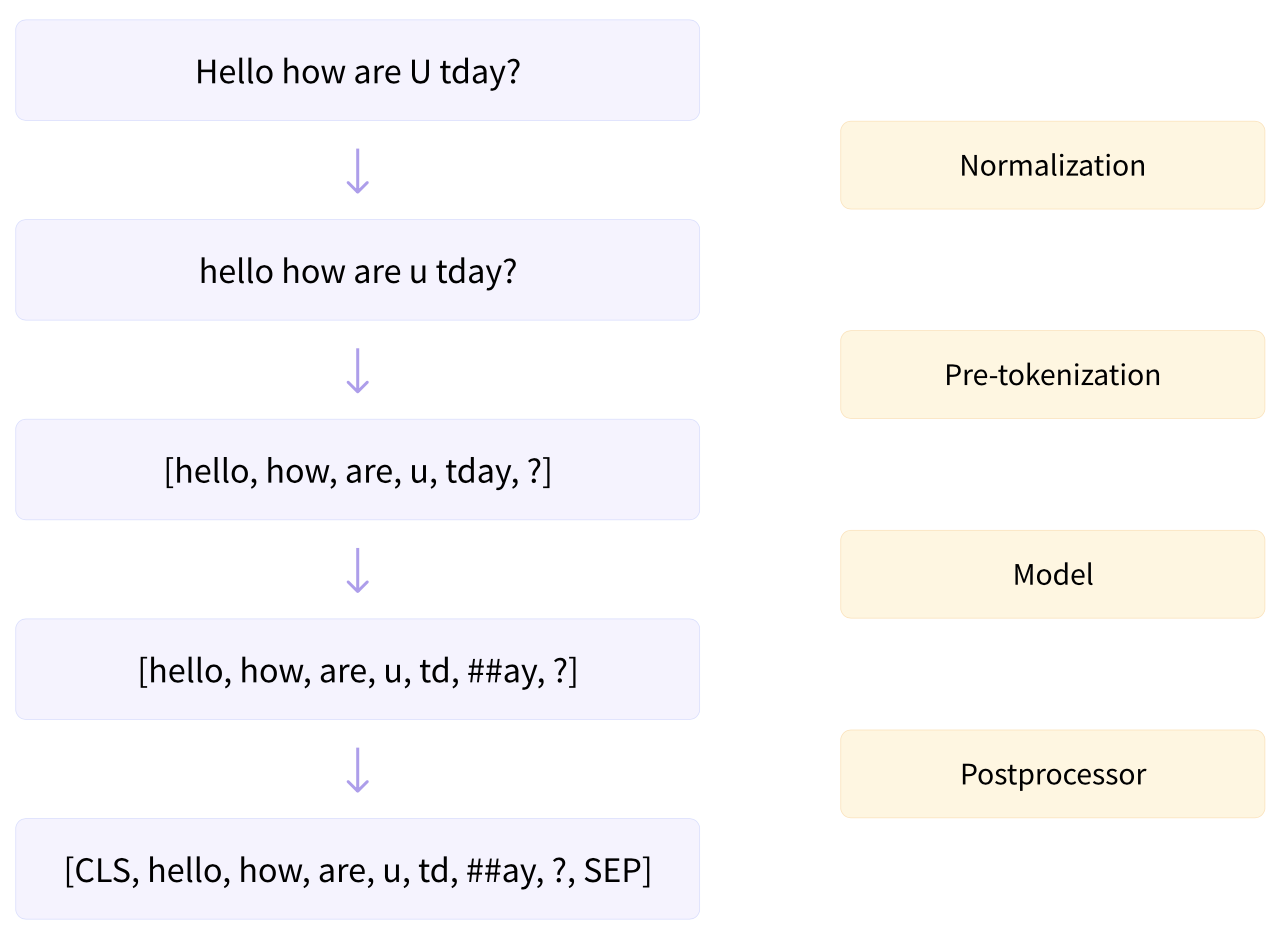

Before splitting a text into subtokens (according to its model), the tokenizer performs two steps:
- normalization
- pre-tokenization

The normalization step involves some general cleanup, such as removing needless whitespace, lowercasing, and/or removing accents. If you’re familiar with Unicode normalization (such as NFC or NFKC), this is also something the tokenizer may apply.

```python
- import unicodedata
- unicodedata.normalize("NFC", "e\u0301")  # returns "é"
- unicodedata.normalize("NFKC", "① 𝓐 Ⅷ ²")  # returns "1 A VIII 2"
```

The 🤗 Transformers tokenizer has an attribute called `backend_tokenizer` that provides access to the underlying tokenizer from the 🤗 Tokenizers library. We can use this attribute when we want to access the already pretrained tokenizer`s normalizer.



In [1]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("gpt2")  # Bytepairencoding
tokenizer.backend_tokenizer, type(tokenizer.backend_tokenizer) # Note that gpt2 doesnt have normalizer

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

(Tokenizer(version="1.0", truncation=None, padding=None, added_tokens=[{"id":50256, "content":"<|endoftext|>", "single_word":False, "lstrip":False, "rstrip":False, "normalized":True, "special":True}], normalizer=None, pre_tokenizer=ByteLevel(add_prefix_space=False, trim_offsets=True, use_regex=True), post_processor=ByteLevel(add_prefix_space=True, trim_offsets=False, use_regex=True), decoder=ByteLevel(add_prefix_space=True, trim_offsets=True, use_regex=True), model=BPE(dropout=None, unk_token=None, continuing_subword_prefix="", end_of_word_suffix="", fuse_unk=False, byte_fallback=False, ignore_merges=False, vocab={"!":0, """:1, "#":2, "$":3, "%":4, "&":5, "'":6, "(":7, ")":8, "*":9, "+":10, ",":11, "-":12, ".":13, "/":14, "0":15, "1":16, "2":17, "3":18, "4":19, "5":20, "6":21, "7":22, "8":23, "9":24, ":":25, ";":26, "<":27, "=":28, ">":29, "?":30, "@":31, "A":32, "B":33, "C":34, "D":35, "E":36, "F":37, "G":38, "H":39, "I":40, "J":41, "K":42, "L":43, "M":44, "N":45, "O":46, "P":47, "Q":

In [20]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")  # Wordpiece
tokenizer.backend_tokenizer, type(tokenizer.backend_tokenizer)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

(Tokenizer(version="1.0", truncation=None, padding=None, added_tokens=[{"id":0, "content":"[PAD]", "single_word":False, "lstrip":False, "rstrip":False, "normalized":False, "special":True}, {"id":100, "content":"[UNK]", "single_word":False, "lstrip":False, "rstrip":False, "normalized":False, "special":True}, {"id":101, "content":"[CLS]", "single_word":False, "lstrip":False, "rstrip":False, "normalized":False, "special":True}, {"id":102, "content":"[SEP]", "single_word":False, "lstrip":False, "rstrip":False, "normalized":False, "special":True}, {"id":103, "content":"[MASK]", "single_word":False, "lstrip":False, "rstrip":False, "normalized":False, "special":True}], normalizer=BertNormalizer(clean_text=True, handle_chinese_chars=True, strip_accents=None, lowercase=True), pre_tokenizer=BertPreTokenizer(), post_processor=TemplateProcessing(single=[SpecialToken(id="[CLS]", type_id=0), Sequence(id=A, type_id=0), SpecialToken(id="[SEP]", type_id=0)], pair=[SpecialToken(id="[CLS]", type_id=0), S

In [21]:
# Normalize
sequence = "Héllò hôw are ü?"
tokenizer.backend_tokenizer.normalizer.normalize_str(sequence)

'hello how are u?'

To apply custom Normalizers, Huggingface provides several types of normalizers each operation designed for its respective normalization clean operation. We can access different Normalizers using `normalizers` from 🤗 `Tokenizers` Library.

We can combine several of those normalizers by using a `normalizers.Sequence`. For eg, below is a normalizer applying NFD Unicode normalization and removing accents

```python
from tokenizers import normalizers
from tokenizers.normalizers import NFD, StripAccents
normalizer = normalizers.Sequence([NFD(), StripAccents()])
normalizer.normalize_str("Héllò hôw are ü?")
#Ouputs: "Hello how are u?"
```

We can also load tokenizer from a file or load pretrained using Tokenizer class

```python
from tokenizers import Tokenizer

tokenizer = Tokenizer.from_file("yourfile.json")
tokenizer = Tokenizer.from_pretrained("yourcheckpoint")

```

In the above example, since we picked the `bert-base-uncased` checkpoint, the normalization applied lowercasing and removed the accents.

As we will see in the next sections, a tokenizer cannot be trained on raw text alone. Instead, we first need to split the texts into small entities, like words. That’s where the `pre-tokenization` step comes in. A word-based tokenizer can simply split a raw text into words on whitespace and punctuation. Those words will be the boundaries of the subtokens the tokenizer can learn during its training.

To see how a fast tokenizer performs pre-tokenization, we can use the `pre_tokenize_str()` method of the `pre_tokenizer` attribute of the tokenizer object

In [22]:
tokenizer.backend_tokenizer.pre_tokenizer.pre_tokenize_str("Hello, how are  you?")

[('Hello', (0, 5)),
 (',', (5, 6)),
 ('how', (7, 10)),
 ('are', (11, 14)),
 ('you', (16, 19)),
 ('?', (19, 20))]

Notice how the tokenizer is already keeping `track of the offsets`, which is how it can give us the offset mapping we used in the previous section. Here the tokenizer ignores the two spaces and replaces them with just one, but the offset jumps between are and you to account for that.(check offsets of 'are' and 'you')

Since we’re using a BERT tokenizer, the pre-tokenization involves splitting on whitespace and punctuation. Other tokenizers can have different rules for this step. For example, if we use the GPT-2 tokenizer,

In [24]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("gpt2")
tokenizer.backend_tokenizer.pre_tokenizer.pre_tokenize_str("Hello, how are  you?")


# It will split on whitespace and punctuation as well, but it will keep the spaces and replace them with a Ġ symbol,
#enabling it to recover the original spaces if we decode the tokens

[('Hello', (0, 5)),
 (',', (5, 6)),
 ('Ġhow', (6, 10)),
 ('Ġare', (10, 14)),
 ('Ġ', (14, 15)),
 ('Ġyou', (15, 19)),
 ('?', (19, 20))]

In [25]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("t5-small")
tokenizer.backend_tokenizer.pre_tokenizer.pre_tokenize_str("Hello, how are  you?")


# Like the GPT-2 tokenizer, this one keeps spaces and replaces them with a specific token (_),
# but the T5 tokenizer only splits on whitespace, not punctuation.
# Also note that it added a space by default at the beginning of the sentence (before Hello) and ignored the double space between are and you.

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

[('▁Hello,', (0, 6)),
 ('▁how', (7, 10)),
 ('▁are', (11, 14)),
 ('▁you?', (16, 20))]

#### 1. Acquiring a corpus

To train our new tokenizer, we will use a small corpus of text. The steps for acquiring the corpus are similar to the ones we took at the beginning of this chapter, but this time we’ll use the WikiText-2 dataset.

In [1]:
import datasets

dataset = datasets.load_dataset(path="wikitext", name="wikitext-2-raw-v1", split="train")
dataset

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

test-00000-of-00001.parquet:   0%|          | 0.00/733k [00:00<?, ?B/s]

train-00000-of-00001.parquet:   0%|          | 0.00/6.36M [00:00<?, ?B/s]

validation-00000-of-00001.parquet:   0%|          | 0.00/657k [00:00<?, ?B/s]

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

Dataset({
    features: ['text'],
    num_rows: 36718
})

In [3]:
def get_training_corpus(batch_size, dataset):
    total_length = len(dataset)
    for idx in range(0, total_length, batch_size):
        yield dataset["text"][idx:idx+batch_size]

The function `get_training_corpus()` is a generator that will yield batches of 1,000 texts, which we will use to train the tokenizer.

🤗 Tokenizers can also be trained on text files directly. Here’s how we can generate a text file containing all the texts/inputs from WikiText-2 that we can use locally.

In [ ]:
with open("wikitext-2.txt", "w", encoding="utf-8") as f:
    for i in range(len(dataset)):
        f.write(dataset["text"] + "\n")

Next Let's see how to build your own BERT, GPT-2, and XLNet tokenizers, block by block. That will give us an example of each of the three main tokenization algorithms: `WordPiece, BPE, and Unigram`. Let’s start with BERT!

#### 2.1 Building a WordPiece tokenizer(BERT) from scratch

To build a tokenizer with the 🤗 Tokenizers library, we start by instantiating a Tokenizer object with a model, then set its normalizer, pre_tokenizer, post_processor, and decoder attributes to the values we want.

For this example, we’ll create a Tokenizer with a `WordPiece model`.

##### 1. Instantiate the tokenizer object using any WordPiece model

In [4]:
from tokenizers import (
    normalizers, pre_tokenizers, models, processors, trainers, decoders, Tokenizer
)

tokenizer = Tokenizer(model=models.WordPiece(unk_token="[UNK]"))

We have to specify the `unk_token` so the model knows what to return when it encounters vocab it hasn’t seen before. Other arguments we can set here include the vocab of our model (we’re going to train the model, so we don’t need to set this) and `max_input_chars_per_word`, which specifies a maximum length for each word (words longer than the value passed will be split).



##### 2.Normalization
The first step of tokenization is normalization, so let’s begin with that. Since BERT is widely used, there is a `BertNormalizer` with the below classic options
- `lowercase`
- `strip_accents`
- `clean_text` to remove all control characters and replace repeating spaces with a single one
- `handle_chinese_chars`, which places spaces around Chinese characters.

To replicate the bert-base-uncased tokenizer, we can just set this normalizer.

In [5]:
tokenizer.normalizer = normalizers.BertNormalizer(lowercase=True)

Note however, when building a new tokenizer you won’t have access to such a handy normalizer already implemented in the 🤗 Tokenizers library, so let’s see how to create the BERT normalizer by hand.

The library provides a Lowercase normalizer and a StripAccents normalizer, and you can compose several normalizers using a Sequence.

In [6]:
from tokenizers import normalizers
from tokenizers.normalizers import Lowercase, StripAccents, NFC, NFKC, NFD

tokenizer.normalizer = normalizers.Sequence(
    [NFD(), Lowercase(), StripAccents()]
)

We’re also using an NFD Unicode normalizer, as otherwise the StripAccents normalizer won’t properly recognize the accented characters and thus won’t strip them out.

As we’ve seen before, we can use the `normalize_str()` method of the normalizer to check out the effects it has on a given text.

In [7]:
tokenizer.normalizer.normalize_str("Héllò hôw are ü?")

'hello how are u?'

##### 3. Pre-tokenization
Next is the pre-tokenization step. Again, there is a prebuilt BertPreTokenizer that we can use.

In [8]:
tokenizer.pre_tokenizer = pre_tokenizers.BertPreTokenizer()

Or we can build it from scratch

In [9]:
tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()

Note that the Whitespace pre-tokenizer splits on whitespace and all characters that are not letters, digits, or the underscore character, so it technically splits on whitespace and punctuation.

In [10]:
tokenizer.pre_tokenizer.pre_tokenize_str("Let's test my pre-tokenizer.")

[('Let', (0, 3)),
 ("'", (3, 4)),
 ('s', (4, 5)),
 ('test', (6, 10)),
 ('my', (11, 13)),
 ('pre', (14, 17)),
 ('-', (17, 18)),
 ('tokenizer', (18, 27)),
 ('.', (27, 28))]

If you only want to split on whitespace, you should use the `WhitespaceSplit` pre-tokenizer instead.

In [11]:
tokenizer.pre_tokenizer = pre_tokenizers.WhitespaceSplit()
tokenizer.pre_tokenizer.pre_tokenize_str("Let's test my pre-tokenizer.")

[("Let's", (0, 5)),
 ('test', (6, 10)),
 ('my', (11, 13)),
 ('pre-tokenizer.', (14, 28))]

Like with normalizers, you can use a Sequence to compose several pre-tokenizers.

In [12]:
tokenizer.pre_tokenizer = pre_tokenizers.Sequence(
    [pre_tokenizers.WhitespaceSplit(), pre_tokenizers.Punctuation()]
)
tokenizer.pre_tokenizer.pre_tokenize_str("Let's test my pre-tokenizer.")

[('Let', (0, 3)),
 ("'", (3, 4)),
 ('s', (4, 5)),
 ('test', (6, 10)),
 ('my', (11, 13)),
 ('pre', (14, 17)),
 ('-', (17, 18)),
 ('tokenizer', (18, 27)),
 ('.', (27, 28))]

##### 4. Modeling
The next step in the tokenization pipeline is running the inputs through the model. We already specified our model in the initialization, but we still need to train it, which will require a `WordPieceTrainer`. The main thing to remember when instantiating a trainer in 🤗 Tokenizers is that you need to pass it all the special tokens you intend to use — otherwise it won’t add them to the vocabulary, since they are not in the training corpus.

In [14]:
from tokenizers import trainers

special_tokens = ["[UNK]", "[PAD]", "[CLS]", "[SEP]", "[MASK]"]
trainer = trainers.WordPieceTrainer(vocab_size=25000, special_tokens=special_tokens)

As well as specifying the `vocab_size` and `special_tokens`, we can set the `min_frequency` (the number of times a token must appear to be included in the vocabulary) or change the `continuing_subword_prefix` (if we want to use something different from ##).

To train our model using the iterator we defined earlier, we just have to execute the below command.

In [15]:
tokenizer.train_from_iterator(get_training_corpus(batch_size=1000, dataset=dataset), trainer=trainer)

We can also use text files to train our tokenizer, which would look like this (we reinitialize the model with an empty WordPiece beforehand)

In [ ]:
tokenizer.model = models.WordPiece(unk_token="[UNK]")
tokenizer.train(["wikitext-2.txt"], trainer=trainer)

In both cases, we can then test the tokenizer on a text by calling the `encode()` method

In [18]:
encoding = tokenizer.encode("Let's test this tokenizer.")
encoding

Encoding(num_tokens=9, attributes=[ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, overflowing])

The encoding obtained is an Encoding, which contains all the necessary outputs of the tokenizer in its various attributes: ids, type_ids, tokens, offsets, attention_mask, special_tokens_mask, and overflowing.

In [19]:
encoding.tokens

['let', "'", 's', 'test', 'this', 'tok', '##eni', '##zer', '.']

##### 5. Post-Processing

The last step in the tokenization pipeline is post-processing. We need to add the `[CLS]` token at the beginning and the `[SEP]` token at the end (or after each sentence, if we have a pair of sentences). We will use a `TemplateProcessor` for this, but first we need to know the IDs of the `[CLS]` and `[SEP]` tokens in the vocabulary.

In [25]:
cls_token_id = tokenizer.token_to_id("[CLS]")
sep_token_id = tokenizer.token_to_id("[SEP]")
cls_token_id, sep_token_id

(2, 3)

To write the template for the `TemplateProcessor`, we have to specify how to treat a single sentence and a pair of sentences. For both, we write the special tokens we want to use; the first (or single) sentence is represented by A, while the second sentence (if encoding pair) is represented by B. For each of these (special tokens and sentences), we also specify the corresponding token type ID after a colon.

The classic BERT template is thus defined as follows.

In [33]:
from tokenizers import processors

tokenizer.post_processor = processors.TemplateProcessing(
    single=f"[CLS]:0 $A:0 [SEP]:0",
    pair=f"[CLS]:0 $A:0 [SEP]:0 $B:1 [SEP]:1",
    special_tokens=[("[CLS]", cls_token_id), ("[SEP]", sep_token_id)],
)

Note that we need to pass along the IDs of the special tokens, so the tokenizer can properly convert them to their IDs.

Once this is added, going back to our previous example will give.

In [34]:
encoding = tokenizer.encode("Let's test this tokenizer")
print(encoding.tokens)

['[CLS]', 'let', "'", 's', 'test', 'this', 'tok', '##eni', '##zer', '[SEP]']


And on a pair of sentences, we get the proper result:

In [35]:
encoding = tokenizer.encode("Let's test this tokenizer...", "on a pair of sentences.")
print(encoding.tokens)
print(encoding.type_ids)
print(encoding.ids)

['[CLS]', 'let', "'", 's', 'test', 'this', 'tok', '##eni', '##zer', '.', '.', '.', '[SEP]', 'on', 'a', 'pair', 'of', 'sentences', '.', '[SEP]']
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1]
[2, 3005, 11, 61, 3597, 1511, 24300, 18889, 6600, 18, 18, 18, 3, 1363, 43, 4140, 1339, 9438, 18, 3]


We’ve almost finished building this tokenizer from scratch — the last step is to include a decoder.

In [36]:
tokenizer.decoder = decoders.WordPiece(prefix="##")

In [37]:
# Let’s test it on our previous encoding
tokenizer.decode(encoding.ids)

"let ' s test this tokenizer... on a pair of sentences."

Great! We can save our tokenizer in a single JSON file like this

In [38]:
tokenizer.save("tokenizer.json")

We can then reload that file in a Tokenizer object with the `from_file()` method

In [40]:
new_tokenizer = tokenizer.from_file("tokenizer.json")

To use this tokenizer in 🤗 Transformers, we have to wrap it in a `PreTrainedTokenizerFast`. We can either use the generic class or, if our tokenizer corresponds to an existing model, use that class (here, `BertTokenizerFast`). If you apply this lesson to build a brand new tokenizer, you will have to use the first option.

To wrap the tokenizer in a `PreTrainedTokenizerFast`, we can either pass the tokenizer we built as a `tokenizer_object` or pass the tokenizer file we saved as `tokenizer_file`. The key thing to remember is that we have to manually set all the special tokens, since that class can’t infer from the tokenizer object which token is the mask token, the [CLS] token, etc.

In [41]:
from transformers import PreTrainedTokenizerFast

wrapped_tokenizer = PreTrainedTokenizerFast(tokenizer_object=tokenizer,
                                            # tokenizer_file="tokenizer.json", # for file based loading
                                            unk_token="[UNK]",
                                            pad_token="[PAD]",
                                            cls_token="[CLS]",
                                            sep_token="[SEP]",
                                            mask_token="[MASK]",
                                            )

If you are using a specific tokenizer class (like BertTokenizerFast), you will only need to specify the special tokens that are different from the default ones (here, none)

In [42]:
from transformers import BertTokenizerFast

wrapped_tokenizer = BertTokenizerFast(tokenizer_object=tokenizer)

You can then use this tokenizer like any other 🤗 Transformers tokenizer. You can save it with the `save_pretrained()` method, or upload it to the Hub with the `push_to_hub()` method.

Now that we’ve seen how to build a `WordPiece` tokenizer, let’s do the same for a `BPE` tokenizer.

#### 2.2 BPE Tokenizer(GPT2)

In [46]:
from tokenizers import Tokenizer, normalizers, pre_tokenizers, models, processors, decoders, trainers

from tokenizers import ByteLevelBPETokenizer

from transformers import PreTrainedTokenizerFast, GPT2TokenizerFast

tokenizer = Tokenizer(model=models.BPE())  #  no need to specify an unk_token because GPT-2 uses byte-level BPE, which doesn’t require it.

# Note: GPT-2 does not use a normalizer, so we skip that step and go directly to the pre-tokenization.

tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False) # not add a space at the beginning of a sentence. Check gpt2 pretokenization part in previous sections where it adds space by default

special_tokens = ["<|endoftext|>"]  # for gpt2, only special token is the end-of-text token
trainer = trainers.BpeTrainer(vocab_size=25000, special_tokens=special_tokens)
tokenizer.train_from_iterator(get_training_corpus(batch_size=1000, dataset=dataset), trainer=trainer)

# tokenizer can also be trained on text files instead
# tokenizer.model = models.BPE() # reinitialize the model
# tokenizer.train(["wikitext-2.txt"], trainer=trainer)

#  Byte-level post-processing for the GPT-2 tokenizer
tokenizer.post_processor = processors.ByteLevel(trim_offsets=False)

tokenizer.decoder = decoders.ByteLevel()

sequence = "Let's test this tokenizer."
encoding = tokenizer.encode(sequence)
print(encoding.tokens)
print(tokenizer.decode(encoding.ids))

tokenizer.save("bpe.json")

wrapped_tokenizer = PreTrainedTokenizerFast(tokenizer_file="bpe.json",
                                            bos_token="<|endoftext|>",
                                            eos_token="<|endoftext|>",
                                            )
wrapped_tokenizer.save_pretrained("bpe_tokenizer")
# wrapped_tokenizer = GPT2TokenizerFast(tokenizer_object=tokenizer)  # when we know the class

['L', 'et', "'", 's', 'Ġtest', 'Ġthis', 'Ġto', 'ken', 'izer', '.']
Let's test this tokenizer.


('bpe_tokenizer/tokenizer_config.json',
 'bpe_tokenizer/special_tokens_map.json',
 'bpe_tokenizer/tokenizer.json')

The `trim_offsets = False` option in post processing indicates to the post-processor that we should leave the offsets of tokens that begin with ‘Ġ’ as they are: this way the start of the offsets will point to the space before the word, not the first character of the word (since the space is technically part of the token).

Let’s have a look at the result with the text we just encoded, where 'Ġtest' is the token at index 4

In [49]:
sentence = "Let's test this tokenizer."
encoding = tokenizer.encode(sentence)
print(encoding.tokens)
print(encoding.offsets)
print(encoding.offsets[4])
start, end = encoding.offsets[4]
sentence[start:end]

['L', 'et', "'", 's', 'Ġtest', 'Ġthis', 'Ġto', 'ken', 'izer', '.']
[(0, 1), (1, 3), (3, 4), (4, 5), (5, 10), (10, 15), (15, 18), (18, 21), (21, 25), (25, 26)]
(5, 10)


' test'

#### 2.3 Building a Unigram tokenizer(XLNet SentencePiece Tokenizer) from scratch

In [51]:
from tokenizers import Tokenizer, normalizers, pre_tokenizers, models, processors, decoders, Regex

from transformers import PreTrainedTokenizerFast, XLNetTokenizerFast

tokenizer = Tokenizer(model=models.Unigram()) # Initiatin the unigram model for the tokenizer

# For the normalization, XLNet uses a few replacements (which come from SentencePiece)
tokenizer.normalizer = normalizers.Sequence(
    [
        normalizers.Replace("``", '"'),
        normalizers.Replace("''", '"'),
        normalizers.NFD(),
        normalizers.StripAccents(),
        normalizers.Replace(Regex(" {2,}"), " ")
    ]
)  # This replaces “ and ” with ” and any sequence of two or more spaces with a single space, as well as removing the accents in the texts to tokenize

tokenizer.pre_tokenizer = pre_tokenizers.Metaspace()  # pre-tokenizer to use for any SentencePiece tokenizer is Metaspace

print(tokenizer.pre_tokenizer.pre_tokenize_str("Let's test the pre-tokenizer!"))

special_tokens = ["<cls>", "<sep>", "<unk>", "<pad>", "<mask>", "<s>", "</s>"]
trainer = trainers.UnigramTrainer(vocab_size=25000, special_tokens=special_tokens, unk_token="<unk>")
tokenizer.train_from_iterator(get_training_corpus(batch_size=1000, dataset=dataset), trainer=trainer)

# A very important argument not to forget for the UnigramTrainer is the unk_token. We can also pass along other arguments specific to the Unigram algorithm, such as the shrinking_factor for each step where we remove tokens (defaults to 0.75) or the max_piece_length to specify the maximum length of a given token (defaults to 16).

encoding = tokenizer.encode("Let's test this tokenizer.")
print(encoding.tokens)

cls_token_id = tokenizer.token_to_id("<cls>")
sep_token_id = tokenizer.token_to_id("<sep>")
print(cls_token_id, sep_token_id)

tokenizer.post_processor = processors.TemplateProcessing(
    single="$A:0 <sep>:0 <cls>:2",
    pair="$A:0 <sep>:0 $B:1 <sep>:1 <cls>:2",
    special_tokens=[("<sep>", sep_token_id), ("<cls>", cls_token_id)],
)

encoding = tokenizer.encode("Let's test this tokenizer...", "on a pair of sentences!")
print(encoding.tokens)
print(encoding.ids)
print(encoding.type_ids)

tokenizer.decoder = decoders.Metaspace()
print(tokenizer.decode(encoding.ids))

wrapped_tokenizer = PreTrainedTokenizerFast(
    tokenizer_object=tokenizer,
    bos_token="<s>",
    eos_token="</s>",
    unk_token="<unk>",
    pad_token="<pad>",
    cls_token="<cls>",
    sep_token="<sep>",
    mask_token="<mask>",
    padding_side="left",
)

# wrapped_tokenizer = XLNetTokenizerFast(tokenizer_object=tokenizer) # alternatively we can do this

[("▁Let's", (0, 5)), ('▁test', (5, 10)), ('▁the', (10, 14)), ('▁pre-tokenizer!', (14, 29))]
['▁Let', "'", 's', '▁test', '▁this', '▁to', 'ken', 'izer', '.']
0 1
['▁Let', "'", 's', '▁test', '▁this', '▁to', 'ken', 'izer', '.', '.', '.', '<sep>', '▁', 'on', '▁', 'a', '▁pair', '▁of', '▁sentence', 's', '!', '<sep>', '<cls>']
[6429, 8029, 9, 1091, 88, 17, 5871, 15951, 11, 11, 11, 1, 7, 26, 7, 15, 1399, 12, 1637, 9, 535, 1, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2]
Let's test this tokenizer... on a pair of sentences!


#### General Pipeline for tokenization from scratch

```python
from tokenizers import Tokenizer, models, normalizers, ....
from transformers import PreTrainedFastTokenizer

tokenizer = Tokenizer(models.BPE())
tokenizer.normalizer = normalizers.NFKC()
tokenizer.pre_tokenizer = ... # some pre tokenizer
tokenizer.decoder = ...
tokenizer.processor = ...
etc...

## Optional training phase, not required
## if you loaded from an existing model.

trainer = trainers.BpeTrainer(vocab_size=80000)
tokenizer.train(trainer, ["myfile.txt"])

## Training

tokenizer.encode("my string").tokens
                              
tokenizer.save('mytokenizer.json')

# wrap as fast

wrapped_tokenizer = PreTrainedFastTokenizer(....)

```

### Sub-Word Tokenizers in depth from scratch

We’ll dive into the three main subword tokenization algorithms:
- BPE (used by GPT-2 and others)
- WordPiece (used for example by BERT)
- Unigram (used by T5 and others).

Before we get started, here’s a quick overview of how they each work.







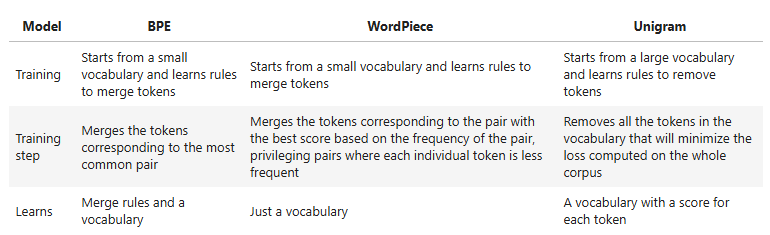

| Encoding | Splits a word into characters and applies the merges learned during training | Finds the longest subword starting from the beginning that is in the vocabulary, then does the same for the rest of the word | Finds the most likely split into tokens, using the scores learned during training

Now let’s dive into BPE!

1. Byte-Pair Encoding tokenization
Byte-Pair Encoding (BPE) was initially developed as an algorithm to compress texts, and then used by OpenAI for tokenization when pretraining the GPT model. It’s used by a lot of Transformer models, including GPT, GPT-2, RoBERTa, BART, and DeBERTa.

1.1 Training algorithm
BPE training starts by computing the unique set of words used in the corpus (after the normalization and pre-tokenization steps are completed), then building the vocabulary by taking all the symbols used to write those words. As a very simple example, let’s say our corpus uses these five words:

"hug", "pug", "pun", "bun", "hugs"
The base vocabulary will then be ["b", "g", "h", "n", "p", "s", "u"]. For real-world cases, that base vocabulary will contain all the ASCII characters, at the very least, and probably some Unicode characters as well. If an example you are tokenizing uses a character that is not in the training corpus, that character will be converted to the unknown token. That’s one reason why lots of NLP models are very bad at analyzing content with emojis, for instance.

The GPT-2 and RoBERTa tokenizers (which are pretty similar) have a clever way to deal with this: they don’t look at words as being written with Unicode characters, but with bytes. This way the base vocabulary has a small size (256), but every character you can think of will still be included and not end up being converted to the unknown token. This trick is called byte-level BPE.

After getting this base vocabulary, we add new tokens until the desired vocabulary size is reached by learning merges, which are rules to merge two elements of the existing vocabulary together into a new one. So, at the beginning these merges will create tokens with two characters, and then, as training progresses, longer subwords.

At any step during the tokenizer training, the BPE algorithm will search for the most frequent pair of existing tokens (by “pair,” here we mean two consecutive tokens in a word). That most frequent pair is the one that will be merged, and we rinse and repeat for the next step.

Going back to our previous example, let’s assume the words had the following frequencies:

("hug", 10), ("pug", 5), ("pun", 12), ("bun", 4), ("hugs", 5)
meaning "hug" was present 10 times in the corpus, "pug" 5 times, "pun" 12 times, "bun" 4 times, and "hugs" 5 times. We start the training by splitting each word into characters (the ones that form our initial vocabulary) so we can see each word as a list of tokens:

("h" "u" "g", 10), ("p" "u" "g", 5), ("p" "u" "n", 12), ("b" "u" "n", 4), ("h" "u" "g" "s", 5)
Then we look at pairs. The pair ("h", "u") is present in the words "hug" and "hugs", so 15 times total in the corpus. It’s not the most frequent pair, though: that honor belongs to ("u", "g"), which is present in "hug", "pug", and "hugs", for a grand total of 20 times in the vocabulary.

Thus, the first merge rule learned by the tokenizer is ("u", "g") -> "ug", which means that "ug" will be added to the vocabulary, and the pair should be merged in all the words of the corpus. At the end of this stage, the vocabulary and corpus look like this:

Vocabulary: ["b", "g", "h", "n", "p", "s", "u", "ug"]
Corpus: ("h" "ug", 10), ("p" "ug", 5), ("p" "u" "n", 12), ("b" "u" "n", 4), ("h" "ug" "s", 5)
Now we have some pairs that result in a token longer than two characters: the pair ("h", "ug"), for instance (present 15 times in the corpus). The most frequent pair at this stage is ("u", "n"), however, present 16 times in the corpus, so the second merge rule learned is ("u", "n") -> "un". Adding that to the vocabulary and merging all existing occurrences leads us to:

Vocabulary: ["b", "g", "h", "n", "p", "s", "u", "ug", "un"]
Corpus: ("h" "ug", 10), ("p" "ug", 5), ("p" "un", 12), ("b" "un", 4), ("h" "ug" "s", 5)
Now the most frequent pair is ("h", "ug"), so we learn the merge rule ("h", "ug") -> "hug", which gives us our first three-letter token. After the merge, the corpus looks like this:

Vocabulary: ["b", "g", "h", "n", "p", "s", "u", "ug", "un", "hug"]
Corpus: ("hug", 10), ("p" "ug", 5), ("p" "un", 12), ("b" "un", 4), ("hug" "s", 5)
And we continue like this until we reach the desired vocabulary size.

1.2 Tokenization algorithm
Tokenization follows the training process closely, in the sense that new inputs are tokenized by applying the following steps:

Normalization
Pre-tokenization
Splitting the words into individual characters
Applying the merge rules learned in order on those splits
Let’s take the example we used during training, with the three merge rules learned:

("u", "g") -> "ug"
("u", "n") -> "un"
("h", "ug") -> "hug"
The word "bug" will be tokenized as ["b", "ug"]. "mug", however, will be tokenized as ["[UNK]", "ug"] since the letter "m" was not in the base vocabulary. Likewise, the word "thug" will be tokenized as ["[UNK]", "hug"]: the letter "t" is not in the base vocabulary, and applying the merge rules results first in "u" and "g" being merged and then "hu" and "g" being merged.

1.3 Implementing BPE
Now let’s take a look at an implementation of the BPE algorithm. This won’t be an optimized version you can actually use on a big corpus; we just want to show you the code so you can understand the algorithm a little bit better.

First we need a corpus, so let’s create a simple one with a few sentences: